# CS467 MP-A16 – Fitness Workout and Training Plan Recommender
**Hà Văn Quốc Tiến – 29211355728 – CS467A (No. 16)**

Interactive walkthrough: dataset → NLP pipeline → three recommenders → the 3 required test cases → evaluation.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
import pandas as pd
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 200)
from nlp_pipeline import preprocess, extract_constraints, note_sentiment
from recommender import FitnessRecommender
items = pd.read_csv('../data/items.csv'); ratings = pd.read_csv('../data/ratings.csv')
print(items.shape, ratings.shape)
print('sparsity:', round(1 - len(ratings) / (ratings.user_id.nunique() * len(items)), 3))
items.head()

(42, 6) (210, 4)
sparsity: 0.643


,item_id,workout_name,difficulty,duration_min,description,target_muscles_tags
0,W01,Bodyweight HIIT Blast,Intermediate,20,"Fast-paced interval circuit of burpees, jump squats and mountain climbers do...",full_body;cardio;hiit;bodyweight;home
1,W02,Beginner Low-Impact Cardio,Beginner,20,"Gentle marching, step-touches and arm circles that raise heart rate without ...",cardio;low_impact;bodyweight;home;full_body
2,W03,Jump Rope Fat Burner,Intermediate,15,Short skipping intervals with double-unders and high knees to improve coordi...,cardio;calves;shoulders;jump_rope;hiit
3,W04,Tabata Sprint Intervals,Advanced,16,Eight rounds of 20 seconds all-out sprints and skaters followed by 10 second...,cardio;hiit;legs;bodyweight;outdoor
4,W05,Treadmill Incline Walk,Beginner,30,Steady uphill walking on a treadmill that builds an aerobic base and strengt...,cardio;glutes;calves;treadmill;gym;low_impact


## 1. NLP pipeline
Cleaning → phrase normalisation (`no equipment` → `bodyweight`) → tokenisation → stop-words → lemmatisation → synonyms.

In [2]:
for q in ['20 minute home cardio workout with no equipment',
          'Quick ab workout, I hate jumping and have a bad lower back',
          'Half an hour of stretches to relax before bed']:
    print(q, '\n   ->', preprocess(q), extract_constraints(q))

20 minute home cardio workout with no equipment 
   -> ['home', 'cardio', 'bodyweight'] {'duration': 20, 'difficulty': None}
Quick ab workout, I hate jumping and have a bad lower back 
   -> ['quick', 'abs', 'hate', 'jumping', 'bad', 'lower_back'] {'duration': 15, 'difficulty': None}
Half an hour of stretches to relax before bed 
   -> ['half', 'stretching', 'relaxation', 'bed'] {'duration': 30, 'difficulty': None}


In [3]:
rec = FitnessRecommender(items, ratings)
print('TF-IDF matrix:', rec.nlp.item_matrix.shape)
print('U03 profile terms:', rec.nlp.top_terms(rec.profiles['U03'], 10))
print('Note sentiment example:', note_sentiment('Hated it, way too intense.'), note_sentiment('Loved it, felt amazing!'))

TF-IDF matrix: (42, 1055)
U03 profile terms: ['yoga_mat', 'abs', 'flexibility', 'core', 'stretching', 'core abs', 'yoga_mat home', 'home', 'yoga', 'home beginner']
Note sentiment example: -1.0 1.0


## 2. Test case 1 – goal query

In [4]:
rec.content_for_query('20 minute home cardio workout with no equipment')

,item_id,workout_name,difficulty,duration_min,cosine,score,why
1,W38,Lunch Break Express Circuit,Intermediate,15,0.276,0.296,"cardio bodyweight, home, 15 min"
2,W08,Dance Cardio Party,Beginner,30,0.232,0.236,"home cardio, bodyweight"
3,W01,Bodyweight HIIT Blast,Intermediate,20,0.145,0.216,"bodyweight, home, cardio, 20 min"
4,W02,Beginner Low-Impact Cardio,Beginner,20,0.136,0.209,"cardio, bodyweight, home, 20 min"
5,W41,Stair Climb Cardio,Intermediate,20,0.113,0.190,"cardio, bodyweight, 20 min"


## 3. Test case 2 – user who rated core & stretching highly (U03)

In [5]:
ratings[ratings.user_id == 'U03'].merge(items[['item_id', 'workout_name']]).sort_values('rating', ascending=False).head(8)

,user_id,item_id,rating,workout_note,workout_name
6,U03,W23,5,"Loved it, the core work felt amazing.",10-Minute Core Crusher
7,U03,W24,5,"Awesome workout, felt energized after.",Pilates Core Foundations
9,U03,W29,5,"Perfect for my goals, the flexibility work was spot on.",Full-Body Stretching Routine
8,U03,W28,5,Great flow and the core work was exactly what I needed.,Hanging Leg Raise Abs
15,U03,W42,5,Great flow and the core work was exactly what I needed.,Core and Stretch Combo
10,U03,W30,5,"Awesome workout, felt energized after.",Morning Yoga Flow
1,U03,W08,4,"Nice routine, would do again.",Dance Cardio Party
11,U03,W34,4,"Solid session, the yoga flow was challenging but good.",Power Yoga Strength Flow


In [6]:
display(rec.content_for_user('U03'))
display(rec.cf_for_user('U03'))
display(rec.hybrid_for_user('U03'))
display(rec.popularity('U03'))

,item_id,workout_name,difficulty,duration_min,score,why
1,W32,Post-Run Cooldown Stretch,Beginner,10,0.127,"stretching, flexibility, recovery"
2,W25,Plank Variations Challenge,Intermediate,15,0.127,"core, plank, home"
3,W31,Hip Mobility for Desk Workers,Beginner,15,0.117,"stretching, yoga_mat, hip"
4,W26,Lower Back and Core Stability,Beginner,20,0.112,"core, yoga_mat, bodyweight"
5,W16,Glute Bridge and Leg Burner,Beginner,20,0.088,"home, bodyweight home, home beginner"


,item_id,workout_name,difficulty,duration_min,score,why
1,W26,Lower Back and Core Stability,Beginner,20,4.577,"liked by similar users U11(5*), U12(5*)"
2,W32,Post-Run Cooldown Stretch,Beginner,10,4.246,"liked by similar users U06(5*), U04(5*), U09(4*)"
3,W20,Machine Circuit for Beginners,Beginner,35,4.112,"liked by similar users U10(4*), U14(4*), U04(5*)"
4,W16,Glute Bridge and Leg Burner,Beginner,20,4.052,"liked by similar users U10(5*), U11(4*), U07(3*)"
5,W25,Plank Variations Challenge,Intermediate,15,4.050,"liked by similar users U14(4*), U11(4*), U12(3*)"


,item_id,workout_name,difficulty,duration_min,score,why
1,W26,Lower Back and Core Stability,Beginner,20,0.940,"CF 4.58*, content 0.11 (core, yoga_mat)"
2,W32,Post-Run Cooldown Stretch,Beginner,10,0.894,"CF 4.25*, content 0.13 (stretching, flexibility)"
3,W25,Plank Variations Challenge,Intermediate,15,0.833,"CF 4.05*, content 0.13 (core, plank)"
4,W16,Glute Bridge and Leg Burner,Beginner,20,0.676,"CF 4.05*, content 0.09 (home, bodyweight home)"
5,W31,Hip Mobility for Desk Workers,Beginner,15,0.611,"CF 3.47*, content 0.12 (stretching, yoga_mat)"


,item_id,workout_name,difficulty,duration_min,score,why
1,W01,Bodyweight HIIT Blast,Intermediate,20,3.797,avg 4.00 from 6 ratings
2,W16,Glute Bridge and Leg Burner,Beginner,20,3.686,avg 3.83 from 6 ratings
3,W12,Push-Up Progression Upper Body,Beginner,20,3.596,avg 3.75 from 4 ratings
4,W03,Jump Rope Fat Burner,Intermediate,15,3.596,avg 3.75 from 4 ratings
5,W25,Plank Variations Challenge,Intermediate,15,3.575,avg 3.67 from 6 ratings


## 4. Test case 3 – cold start

In [7]:
rec.cold_start("I'm a beginner with a stiff lower back and I want to get more flexible.")

,item_id,workout_name,difficulty,duration_min,score,why,popularity
1,W26,Lower Back and Core Stability,Beginner,20,0.370,"lower_back, beginner | pop 4.03",4.03
2,W29,Full-Body Stretching Routine,Beginner,20,0.285,"flexibility, beginner | pop 3.80",3.80
3,W31,Hip Mobility for Desk Workers,Beginner,15,0.278,"lower_back, beginner | pop 2.90",2.90
4,W42,Core and Stretch Combo,Beginner,30,0.276,"flexibility, beginner | pop 4.02",4.02
5,W35,Bedtime Relaxation Stretch,Beginner,15,0.272,"flexibility, beginner | pop 3.88",3.88


## 5. Try your own query

In [8]:
my_query = 'advanced kettlebell conditioning under 30 minutes'
rec.content_for_query(my_query)

,item_id,workout_name,difficulty,duration_min,cosine,score,why
1,W39,CrossFit Style WOD,Advanced,35,0.291,0.416,"kettlebell, conditioning, advanced, 35 min"
2,W14,Kettlebell Swing Circuit,Intermediate,25,0.270,0.299,"kettlebell, conditioning, 25 min"
3,W04,Tabata Sprint Intervals,Advanced,16,0.116,0.246,"conditioning, advanced"
4,W17,Pull-Up Bar Back Builder,Advanced,30,0.041,0.233,"advanced, 30 min"
5,W28,Hanging Leg Raise Abs,Advanced,20,0.067,0.220,advanced


## 6. Offline evaluation (5 random splits)

In [9]:
from evaluate import run_evaluation
summary, ub = run_evaluation()

Evaluation over 5 random splits (3 hidden ratings per user, relevant = rating >= 4)
                 Precision@5       Recall@5      HitRate@5           RMSE            MAE
method                                                                                  
Popularity     0.046 ± 0.019  0.129 ± 0.055  0.232 ± 0.094  1.333 ± 0.111  1.114 ± 0.126
Content (NLP)   0.225 ± 0.04  0.727 ± 0.106  0.891 ± 0.159  1.159 ± 0.056  0.915 ± 0.045
User-CF        0.064 ± 0.017  0.168 ± 0.037  0.267 ± 0.089    1.31 ± 0.05  1.082 ± 0.045
Hybrid         0.198 ± 0.048  0.607 ± 0.115  0.769 ± 0.131  1.182 ± 0.048  0.958 ± 0.034
Oracle upper bound for Precision@5: 0.326


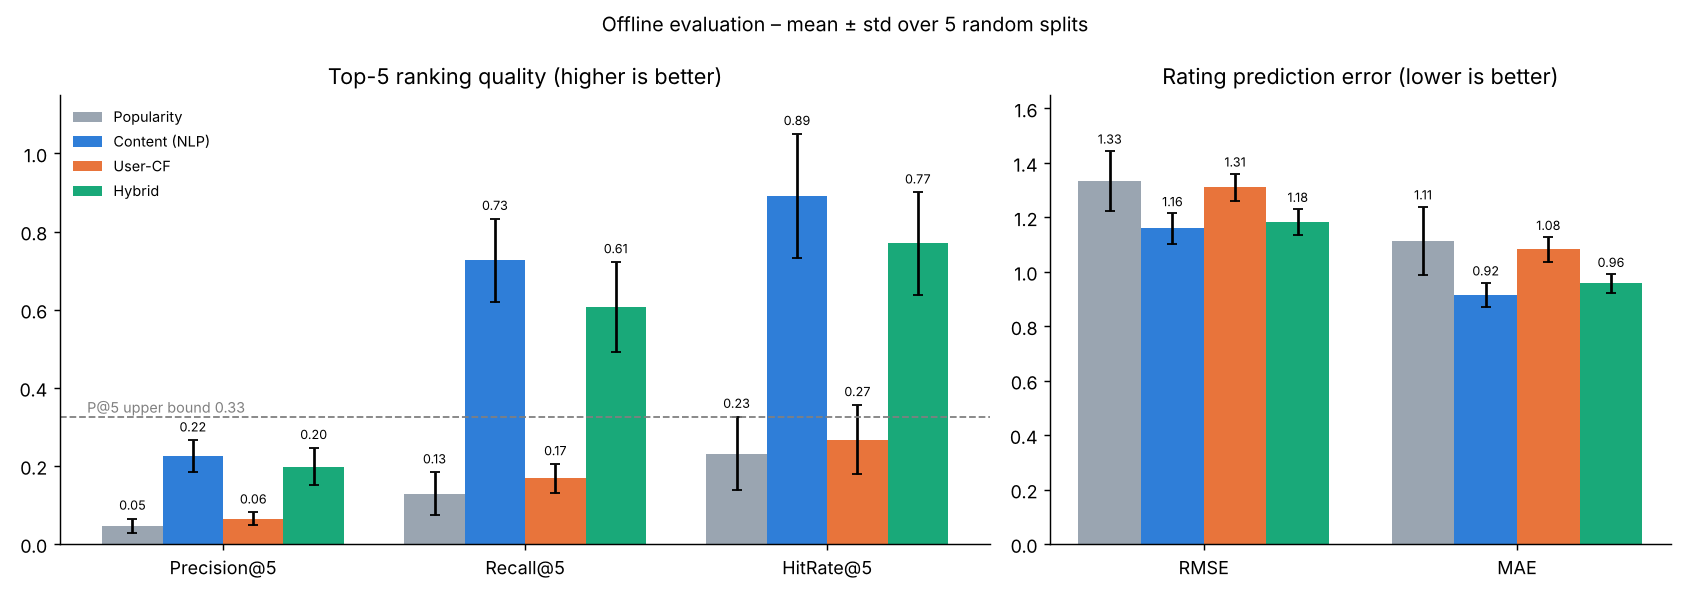

In [10]:
from IPython.display import Image
Image('../results/evaluation_comparison.png')